# Entrega


Modelo multilingüe MiniLM convierte cada reseña en un vector, sin cambiarle los pesos, y una red densa de Keras la clasifica en negativa, neutral o positiva

## 1. Importación de librerías

Se necesitan torch y transformers

In [ ]:
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split

# Modelo de lenguaje
import torch
from transformers import AutoTokenizer, AutoModel

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report


import warnings
warnings.filterwarnings("ignore")
tf.get_logger().setLevel("ERROR")

# Semillas fijas
tf.keras.utils.set_random_seed(42)

dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## 2. Carga de los datos

In [ ]:
path_train = "./datos/train.csv"
path_eval = "./datos/eval.csv"

dataset_train_original = pd.read_csv(path_train)
dataset_eval_original = pd.read_csv(path_eval)

dataset_train = dataset_train_original.copy()
dataset_eval = dataset_eval_original.copy()

print(f"Entrenamiento: {dataset_train.shape} /// Evaluación: {dataset_eval.shape}")

Entrenamiento: (20466, 3) /// Evaluación: (6781, 2)


## 3. Identificación del idioma

Se estima con las 50 palabras más comunes de cada idioma

In [ ]:
import sys
import unicodedata
from collections import Counter

# Signos de puntuación que se cambian por espacios
puntua = {
    i: " "
    for i in range(sys.maxunicode + 1)
    if unicodedata.category(chr(i)).startswith("P")
}

# "he" también es común en español
AMBIGUAS_EN = {"he"}


def procesar_resena(text):
    text = text.lower()
    text = text.translate(puntua)
    return text.split()


def palabras_exclusivas(palabras_por_idioma):
    return {
        idioma: palabras
        - set().union(
            *(otras for otro, otras in palabras_por_idioma.items() if otro != idioma)
        )
        for idioma, palabras in palabras_por_idioma.items()
    }


# Idioma con más palabras exclusivas, o 'es_en' si mezcla español e inglés
def identificar_idioma(resena, palabras_por_idioma, exclusivas):
    conteo = Counter(procesar_resena(resena))

    def puntajes(listas):
        return {
            idioma: sum(n for palabra, n in conteo.items() if palabra in palabras)
            for idioma, palabras in listas.items()
        }

    puntaje = puntajes(exclusivas)
    if max(puntaje.values()) == 0:
        puntaje = puntajes(palabras_por_idioma)
        if max(puntaje.values()) == 0:
            return None
    principal = max(puntaje, key=lambda k: puntaje[k])

    hay_es = any(palabra in exclusivas["es"] for palabra in conteo)
    hay_en = any(palabra in exclusivas["en"] - AMBIGUAS_EN for palabra in conteo)
    if principal in ("es", "en") and hay_es and hay_en:
        return "es_en"
    return principal

In [ ]:
# 50 palabras más comunes por idioma
path_palabras = "./datos/50_palabras_mas_comunes/50_palabras_mas_comunes.csv"

palabras_comunes = pd.read_csv(path_palabras)
palabras_comunes["palabra"] = palabras_comunes["palabra"].map(
    lambda p: procesar_resena(p)[0]
)

palabras_por_idioma = palabras_comunes.groupby("idioma")["palabra"].apply(set).to_dict()
exclusivas = palabras_exclusivas(palabras_por_idioma)

In [ ]:
dataset_train["idioma"] = dataset_train["text"].map(
    lambda t: identificar_idioma(t, palabras_por_idioma, exclusivas)
)
dataset_eval["idioma"] = dataset_eval["text"].map(
    lambda t: identificar_idioma(t, palabras_por_idioma, exclusivas)
)

dataset_train["idioma"].value_counts(dropna=False, normalize=True)

idioma
es       0.652497
en       0.114678
pt_br    0.114043
fr       0.102511
es_en    0.016271
Name: proportion, dtype: float64

## 4. División en entrenamiento y validación

90 % y 10 %, estratificada por idioma y etiqueta.

In [ ]:
# Etiquetas como enteros
etiquetas = sorted(dataset_train["label"].unique())
etiqueta_a_id = {e: i for i, e in enumerate(etiquetas)}

# División 90/10 estratificada por idioma y etiqueta
estrato = dataset_train["idioma"].astype(str) + "|" + dataset_train["label"]

# Los estratos con una sola reseña van a entrenamiento
raros = estrato.map(estrato.value_counts()) < 2

train_df, test_df = train_test_split(
    dataset_train[~raros],
    test_size=0.1,
    random_state=42,
    stratify=estrato[~raros],
)
train_df = pd.concat([train_df, dataset_train[raros]])

print(f"Entrenamiento: {len(train_df)} reseñas | Validación: {len(test_df)} reseñas")

Entrenamiento: 18419 reseñas | Validación: 2047 reseñas


## 5. Vectores de las reseñas

Cada reseña se representa con dos vectores de MiniLM, el del del texto completo y el de la última oración, donde suele estar la opinión final. Se usa el promedio de los tokens max_length=256 para no cortar reseñas largas.

In [ ]:
import re

def ultima_oracion(texto):
    oraciones = [o for o in re.split(r"(?<=[.!?])\s+", texto.strip()) if o]
    return oraciones[-1] if oraciones else texto


# Ejemplo
print(dataset_train["text"][1])
print("Última oración:", ultima_oracion(dataset_train["text"][1]))
print("Etiqueta:", dataset_train["label"][1])

Les cuento como me fue. Compre esta tablet a mediados de año y llego en cuatro dias a mi casa en Guadalajara, sin ningun problema con el paquete. En mi opinion, la resolucion me resulto ser deficiente para ser honesto. La uso sobre todo por las tardes para revisar correos y ver videos mientras ceno. La pantalla tactil termino siendo muy buena en el uso real.
Última oración: La pantalla tactil termino siendo muy buena en el uso real.
Etiqueta: positivo


In [ ]:
# MiniLM multilingüe
nombre_modelo = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
version_modelo = "e8f8c211226b894fcb81acc59f3b34ba3efd5f42"  # versión fija

tokenizador = AutoTokenizer.from_pretrained(nombre_modelo, revision=version_modelo)
modelo_lenguaje = AutoModel.from_pretrained(nombre_modelo, revision=version_modelo)
modelo_lenguaje.eval()
modelo_lenguaje.to(dispositivo)

print(f"Modelo '{nombre_modelo}' cargado")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Modelo 'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2' cargado


In [ ]:
# max_length=256 para no cortar reseñas largas
def obtener_embedding_promedio(texto, tokenizador, modelo, dispositivo):
    entradas = tokenizador(texto, return_tensors="pt", truncation=True, max_length=256).to(dispositivo)
    with torch.no_grad():
        salidas = modelo(**entradas)
    token_embeddings = salidas.last_hidden_state.squeeze(0)[1:-1].cpu().numpy()
    return token_embeddings.mean(axis=0)


# Vector: texto completo + ultima oracion
def generar_embeddings_dataset(textos, tokenizador, modelo, dispositivo):
    embeddings = []
    for i, texto in enumerate(textos):
        vector_texto = obtener_embedding_promedio(texto, tokenizador, modelo, dispositivo)
        vector_ultima = obtener_embedding_promedio(ultima_oracion(texto), tokenizador, modelo, dispositivo)
        embeddings.append(np.concatenate([vector_texto, vector_ultima]))
        if (i + 1) % 5000 == 0:
            print(f"  {i + 1} de {len(textos)} reseñas")
    return np.array(embeddings)

In [34]:
X_train = generar_embeddings_dataset(train_df["text"].tolist(), tokenizador, modelo_lenguaje, dispositivo)
X_test = generar_embeddings_dataset(test_df["text"].tolist(), tokenizador, modelo_lenguaje, dispositivo)
X_eval = generar_embeddings_dataset(dataset_eval["text"].tolist(), tokenizador, modelo_lenguaje, dispositivo)

y_train = train_df["label"].map(etiqueta_a_id).values
y_test = test_df["label"].map(etiqueta_a_id).values

print(f"X_train: {X_train.shape} | X_test: {X_test.shape} | X_eval: {X_eval.shape}")

KeyboardInterrupt: 

## 6. Red neuronal densa

Red con 128 neuronas con ReLU y Dropout de 0,3, con parada temprana por pérdida de validación

In [ ]:
# Entrena hasta 50 épocas y se queda con la de menor pérdida de validación
def entrenar_modelo_con_parada_temprana(
    model, train_dataset, test_dataset, max_epochs=50, patience=3, monitor="val_loss"
):
    modo = "min" if "loss" in monitor else "max"
    parada_temprana = tf.keras.callbacks.EarlyStopping(
        monitor=monitor,
        mode=modo,
        patience=patience,
        restore_best_weights=True,
        verbose=1,
    )

    history = model.fit(
        train_dataset,
        epochs=max_epochs,
        validation_data=test_dataset,
        callbacks=[parada_temprana],
    )

    history.mejor_epoca = parada_temprana.best_epoch
    print(
        f"Mejor época según {monitor}: {history.mejor_epoca + 1} "
        f"(val_loss = {history.history['val_loss'][history.mejor_epoca]:.4f}, "
        f"val_accuracy = {history.history['val_accuracy'][history.mejor_epoca]:.4f})"
    )

    return history


# Métricas
def resumir_historiales(historiales):
    filas = []
    for nombre, h in historiales.items():
        mejor = h.mejor_epoca
        filas.append(
            {
                "modelo": nombre,
                "mejor_epoca": mejor + 1,
                "val_accuracy": h.history["val_accuracy"][mejor],
                "val_loss": h.history["val_loss"][mejor],
                "train_accuracy": h.history["accuracy"][mejor],
            }
        )
    return pd.DataFrame(filas)


def vectores_a_tf(X, y, shuffle):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        ds = ds.shuffle(len(X), seed=42)
    return ds.batch(32).prefetch(tf.data.AUTOTUNE)


# Red: 128 neuronas, Dropout y 3 salidas
def crear_red(n_entradas):
    tf.keras.utils.set_random_seed(42)
    model = tf.keras.Sequential(
        [
            tf.keras.layers.Input(shape=(n_entradas,)),
            tf.keras.layers.Dense(128, activation="relu"),
            tf.keras.layers.Dropout(0.3),
            tf.keras.layers.Dense(3),
        ]
    )
    model.compile(
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        optimizer=tf.keras.optimizers.Adam(),
        metrics=["accuracy"],
    )
    return model

### 6.1 ¿Sirve la última oración?

In [ ]:
historiales = {}

# Solo el texto completo
red_solo_texto = crear_red(384)
historiales["Solo texto completo (384)"] = entrenar_modelo_con_parada_temprana(
    red_solo_texto,
    vectores_a_tf(X_train[:, :384], y_train, shuffle=True),
    vectores_a_tf(X_test[:, :384], y_test, shuffle=False),
)

Epoch 1/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6452 - loss: 0.6482 - val_accuracy: 0.6737 - val_loss: 0.5825
Epoch 2/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6875 - loss: 0.5623 - val_accuracy: 0.6790 - val_loss: 0.5629
Epoch 3/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6975 - loss: 0.5380 - val_accuracy: 0.6864 - val_loss: 0.5515
Epoch 4/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7111 - loss: 0.5208 - val_accuracy: 0.6898 - val_loss: 0.5442
Epoch 5/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7172 - loss: 0.5094 - val_accuracy: 0.6966 - val_loss: 0.5279
Epoch 6/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7225 - loss: 0.4981 - val_accuracy: 0.6996 - val_loss: 0.5216
Epoch 7/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7340 - loss: 0.4860 - val_accuracy: 0.7059 - val_loss: 0.5168
Epoch 8/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7403 - loss: 0.4754 - val_accuracy: 0.

In [ ]:
# Texto completo + última oración
datos_train = vectores_a_tf(X_train, y_train, shuffle=True)
datos_test = vectores_a_tf(X_test, y_test, shuffle=False)

red = crear_red(768)
red.summary()
historial = entrenar_modelo_con_parada_temprana(red, datos_train, datos_test)
historiales["Texto completo + última oración (768)"] = historial

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 128)            │        98,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 98,819 (386.01 KB)

 Trainable params: 98,819 (386.01 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7852 - loss: 0.4586 - val_accuracy: 0.8017 - val_loss: 0.4010
Epoch 2/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8184 - loss: 0.3750 - val_accuracy: 0.8056 - val_loss: 0.3844
Epoch 3/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8329 - loss: 0.3442 - val_accuracy: 0.8227 - val_loss: 0.3737
Epoch 4/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8451 - loss: 0.3229 - val_accuracy: 0.8290 - val_loss: 0.3603
Epoch 5/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8546 - loss: 0.3070 - val_accuracy: 0.8241 - val_loss: 0.3496
Epoch 6/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8599 - loss: 0.2916 - val_accuracy: 0.8300 - val_loss: 0.3438
Epoch 7/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8695 - loss: 0.2751 - val_accuracy: 0.8246 - val_loss: 0.3488
Epoch 8/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8749 - loss: 0.2647 - val_accuracy: 0.

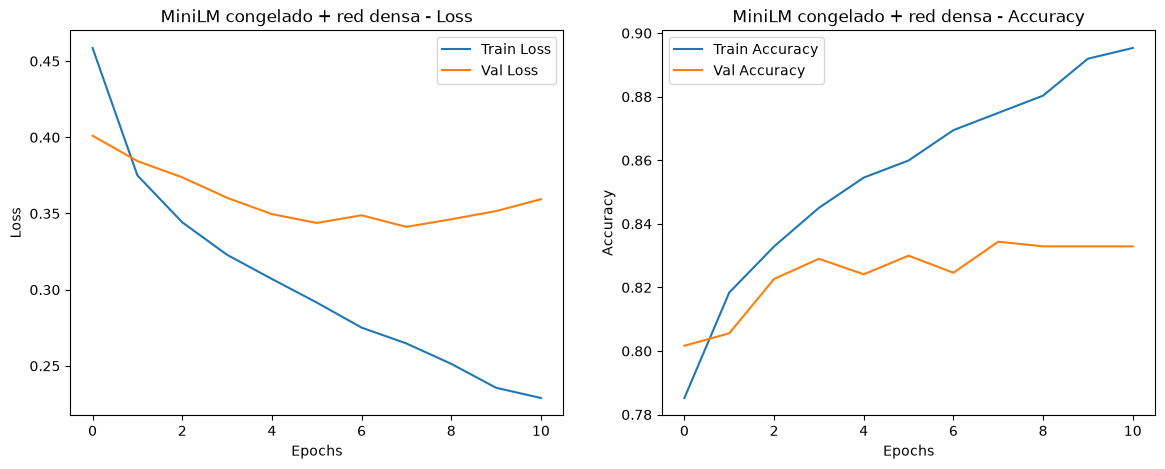

,modelo,mejor_epoca,val_accuracy,val_loss,train_accuracy
1,Texto completo + última oración (768),8,0.834392,0.34123,0.874912
0,Solo texto completo (384),14,0.719101,0.50206,0.774255


In [ ]:
# Curvas de entrenamiento
def plot_history(history, title="Model Performance"):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    ax1.plot(history.history['loss'], label='Train Loss')
    ax1.plot(history.history['val_loss'], label='Val Loss')
    ax1.set_title(f'{title} - Loss')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Loss')
    ax1.legend()

    ax2.plot(history.history['accuracy'], label='Train Accuracy')
    ax2.plot(history.history['val_accuracy'], label='Val Accuracy')
    ax2.set_title(f'{title} - Accuracy')
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('Accuracy')
    ax2.legend()

    plt.show()

plot_history(historial, "MiniLM congelado + red densa")

resumir_historiales(historiales).sort_values("val_accuracy", ascending=False)

Observaciones:

Con la última oración el accuracy sube de 0,719 a 0,834.
La parada temprana se quedó con la época 8. Después la pérdida de validación deja de bajar mientras el accuracy de entrenamiento sigue subiendo.

## 7 vAumentacion

Muchas reseñas en español vienen escritas sin tildes ni ñ. Se agregan copias así de las reseñas en español del entrenamiento y se compara con y sin ellas.

In [ ]:
# Tildes
TILDES = {
    "[áàâäã]": "a",
    "[éèêë]": "e",
    "[íìîï]": "i",
    "[óòôöõ]": "o",
    "[úùûü]": "u",
    "ñ": "n",
    "ç": "c",
}


def quitar_tildes(texto):
    for patron, letra in TILDES.items():
        texto = re.sub(patron, letra, texto)
    return texto


print(quitar_tildes("Llegó en un año y la batería dura muchísimo"))

Llego en un ano y la bateria dura muchisimo


In [ ]:
# Copias sin tildes
copias = train_df[train_df["idioma"].isin(["es", "es_en"])].copy()
copias["text"] = copias["text"].map(quitar_tildes)
copias = copias[copias["text"] != train_df.loc[copias.index, "text"]]
print(f"Copias nuevas: {len(copias)}")

X_copias = generar_embeddings_dataset(copias["text"].tolist(), tokenizador, modelo_lenguaje, dispositivo)
y_copias = copias["label"].map(etiqueta_a_id).values

X_train_aug = np.vstack([X_train, X_copias])
y_train_aug = np.concatenate([y_train, y_copias])

# Misma red y misma validación
red_aug = crear_red(768)
historial_aug = entrenar_modelo_con_parada_temprana(red_aug, vectores_a_tf(X_train_aug, y_train_aug, shuffle=True), datos_test)
historiales["Texto completo + última oración + copias sin tildes (768)"] = historial_aug

Copias nuevas: 8718
  5000 de 8718 reseñas
Epoch 1/50
849/849 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.7932 - loss: 0.4384 - val_accuracy: 0.8061 - val_loss: 0.3951
Epoch 2/50
849/849 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8260 - loss: 0.3582 - val_accuracy: 0.8070 - val_loss: 0.3837
Epoch 3/50
849/849 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8428 - loss: 0.3250 - val_accuracy: 0.8100 - val_loss: 0.3651
Epoch 4/50
849/849 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8564 - loss: 0.3011 - val_accuracy: 0.8310 - val_loss: 0.3590
Epoch 5/50
849/849 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8687 - loss: 0.2812 - val_accuracy: 0.8173 - val_loss: 0.3599
Epoch 6/50
849/849 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8787 - loss: 0.2605 - val_accuracy: 0.8300 - val_loss: 0.3561
Epoch 7/50
849/849 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8875 - loss: 0.2433 - val_accuracy: 0.8373 - val_loss: 0.3495
Epoch 8/50
849/849 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accurac

In [ ]:
# Con y sin aumentación, global y por idioma
pred_sin = red.predict(X_test, verbose=0).argmax(axis=1)
pred_con = red_aug.predict(X_test, verbose=0).argmax(axis=1)

grupos = {"Global": np.full(len(test_df), True)}
for idioma in sorted(test_df["idioma"].unique()):
    grupos[idioma] = (test_df["idioma"] == idioma).values
grupos["español escrito sin tildes"] = (
    test_df["idioma"].isin(["es", "es_en"]) & (test_df["text"].map(quitar_tildes) == test_df["text"])
).values

filas = []
for grupo, filtro in grupos.items():
    filas.append(
        {
            "grupo": grupo,
            "reseñas": int(filtro.sum()),
            "sin aumentación": (pred_sin[filtro] == y_test[filtro]).mean(),
            "con aumentación": (pred_con[filtro] == y_test[filtro]).mean(),
        }
    )
comparacion = pd.DataFrame(filas)
comparacion["diferencia"] = comparacion["con aumentación"] - comparacion["sin aumentación"]
comparacion.round(3)

,grupo,reseñas,sin aumentación,con aumentación,diferencia
0,Global,2047,0.834,0.837,0.003
1,en,234,0.816,0.821,0.004
2,es,1337,0.839,0.836,-0.003
3,es_en,33,0.758,0.758,0.000
4,fr,210,0.814,0.843,0.029
5,pt_br,233,0.854,0.867,0.013
6,español escrito sin tildes,387,0.822,0.819,-0.003


Observaciones:

Con las copias el accuracy pasa de 0,834 a 0,837, apenas 6 reseñas más de 2.047, así que la diferencia no es clara.

## 8. Análisis de errores por idioma

Se elige la red con mejor accuracy en validación y se revisan sus errores.

In [ ]:
resumir_historiales(historiales).sort_values("val_accuracy", ascending=False)

,modelo,mejor_epoca,val_accuracy,val_loss,train_accuracy
2,Texto completo + última oración + copias sin t...,7,0.837323,0.349499,0.887534
1,Texto completo + última oración (768),8,0.834392,0.341230,0.874912
0,Solo texto completo (384),14,0.719101,0.502060,0.774255


In [ ]:
# Red con mejor accuracy en validación
if historial_aug.history["val_accuracy"][historial_aug.mejor_epoca] > historial.history["val_accuracy"][historial.mejor_epoca]:
    modelo_final = red_aug
    print("Modelo final: con aumentación")
else:
    modelo_final = red
    print("Modelo final: sin aumentación")

test_df["pred"] = [etiquetas[c] for c in modelo_final.predict(X_test, verbose=0).argmax(axis=1)]
test_df["acierto"] = test_df["pred"] == test_df["label"]

# Accuracy por idioma
filas = []
for idioma in sorted(test_df["idioma"].unique()):
    parte = test_df[test_df["idioma"] == idioma]
    filas.append({"idioma": idioma, "reseñas": len(parte), "errores": int((~parte["acierto"]).sum()), "accuracy": parte["acierto"].mean()})
filas.append({"idioma": "Total", "reseñas": len(test_df), "errores": int((~test_df["acierto"]).sum()), "accuracy": test_df["acierto"].mean()})
pd.DataFrame(filas).round(3)

Modelo final: con aumentación


,idioma,reseñas,errores,accuracy
0,en,234,42,0.821
1,es,1337,219,0.836
2,es_en,33,8,0.758
3,fr,210,33,0.843
4,pt_br,233,31,0.867
5,Total,2047,333,0.837


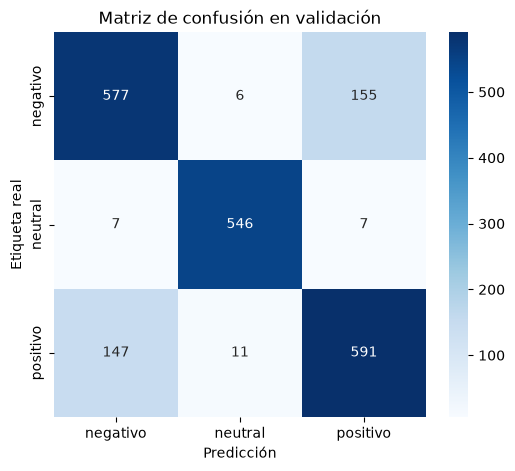

              precision    recall  f1-score   support

    negativo      0.789     0.782     0.786       738
     neutral      0.970     0.975     0.972       560
    positivo      0.785     0.789     0.787       749

    accuracy                          0.837      2047
   macro avg      0.848     0.849     0.848      2047
weighted avg      0.837     0.837     0.837      2047



In [ ]:
# Matriz de confusión
cm = confusion_matrix(test_df["label"], test_df["pred"], labels=etiquetas)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=etiquetas, yticklabels=etiquetas)
plt.xlabel("Predicción")
plt.ylabel("Etiqueta real")
plt.title("Matriz de confusión en validación")
plt.show()

print(classification_report(test_df["label"], test_df["pred"], digits=3))

In [ ]:
# Errores por idioma
errores = test_df[~test_df["acierto"]]
pd.crosstab(errores["idioma"], errores["label"] + " -> " + errores["pred"], colnames=["etiqueta real -> predicción"])

etiqueta real -> predicción,negativo -> neutral,negativo -> positivo,neutral -> negativo,neutral -> positivo,positivo -> negativo,positivo -> neutral
idioma,,,,,,
en,0,22,0,0,17,3
es,5,104,7,3,94,6
es_en,0,6,0,0,2,0
fr,1,14,0,1,16,1
pt_br,0,9,0,3,18,1


In [ ]:
# Dos errores por idioma
pd.set_option("display.max_colwidth", None)
errores.groupby("idioma").head(2)[["idioma", "label", "pred", "text"]]

,idioma,label,pred,text
17722,en,negativo,positivo,"The battery life on these wireless earbuds genuinely impresses me, lasting through my whole workday without needing the case. That said, the touch controls are a constant frustration, registering taps I never intended and ignoring the ones I did. The sound is fine, neither great nor terrible. Some days the comfort wins me over, other days the control issues have me reaching for my old pair. I honestly can't decide if I'd buy them again."
5250,en,positivo,negativo,"The blender crushes ice faster than any I've owned, and the motor stays surprisingly quiet for its size. On the other hand, the jar leaks slightly around the blade seal, enough that I wipe the counter after every use. The lid also feels flimsy compared to the base. I keep going back and forth on whether the good outweighs the annoying details."
10263,es,negativo,positivo,"Lo compre hace un mes por internet y llego en tres dias, desde entonces lo uso a diario en la cocina. El acabado me hizo la vida mas facil, la verdad. Eso si, la calidad esta muy por debajo de la media, no se si me explique bien pero se nota. Yo ya me acostumbre a usarlo, igual cada quien que sopeselo por su cuenta."
10755,fr,neutral,positivo,"Je l'ai acheté il y a quelques mois parce que je devais remplacer celui que j'avais déjà à la maison. Il m'est arrivé en noir, exactement comme je l'avais commandé. Je l'utilise tous les jours au bureau et je n'ai pas eu besoin de demander un échange ni un remboursement. Pour l'instant, il fait le boulot pour ce dont j'avais besoin au quotidien."
7473,es,negativo,positivo,"Lo pedi a mediados de mes y me llego en cuatro dias, en caja sellada. Lo uso en la sala para escuchar musica mientras hago oficio. La verdad, para mi el sonido me parecio pobre por lo que pague. Lo conecte primero por bluetooth y despues por cable, con los audios que acostumbro escuchar los fines de semana."
2603,pt_br,negativo,positivo,"Comprei faz umas duas semanas pro trabalho, chegou no prazo e sem problema. O cabo fica bem curto. Uso todo dia no escritório, é de 20W segundo a caixa. Além disso, recomendo o carregador de olhos fechados. Tem de tudo, como dá pra ver."
19249,pt_br,negativo,positivo,"Comprei essa mochila semana passada pra levar pro trabalho, uso todo dia no busão. Achei que valeu trocar, mas ela decepciona: a anterior rendia mais, essa já chegou meio fraquinha (paguei caro, enfim). Meu filho também usa quando vai pra faculdade e o espaço dele mal cabe tudo. O tecido estica com o peso do notebook e a garrafa, coisa que a antiga aguentava de boa."
4319,fr,positivo,negativo,"Le chargeur tient vraiment ses promesses côté autonomie, il m'a dépanné deux jours complets en voyage, et il recharge vite. Mais il pèse lourd dans le sac, on le sent tout de suite, et le câble fourni semble fragile après quelques semaines. Je ne sais pas si l'encombrement compense ce qu'il apporte, ça dépend vraiment de l'usage de chacun et j'hésite encore."
19848,es_en,negativo,positivo,"La luz de esta lámpara es súper clara, muy bright para leer, eso sí. Pero the base is súper wobbly, se mueve mucho cuando la muevo un poquito. Es un balance difícil porque el diseño es cool, pero la estabilidad es un problema real. No estoy seguro si vale la pena comprarla, you know, porque no es un setup perfecto."
20283,es_en,positivo,negativo,"Me encantó el speaker cuando lo probé en la fiesta, el bass suena bien strong y el battery lasted all weekend. Pero honestly el bluetooth se desconecta cada rato cuando estoy en la cocina, bien annoying. La calidad del audio is really nice though. No sé, sigue siendo hard to decide si me quedo con él o lo cambio."


**Observaciones:**

Le va mejor en portugués (0,867) y francés (0,843), y peor en inglés (0,821) y en la mezcla español-inglés (0,758, solo 33 reseñas).


El 91 % de los errores es confundir positivo con negativo (302 de 333). Las neutrales casi nunca fallan.


Varios errores son reseñas con pros y contras que no se deciden

## 9. Guardar el modelo y crear el envío

In [ ]:
os.makedirs("./modelos", exist_ok=True)
modelo_final.save("./modelos/minilm_red_densa.keras")

# Se vuelve a cargar para comprobar que da lo mismo
modelo_cargado = tf.keras.models.load_model("./modelos/minilm_red_densa.keras")
test_loss, test_acc = modelo_cargado.evaluate(X_test, y_test, verbose=0)
print(f"Accuracy: {str(test_acc)}")

Accuracy: 0.8373228907585144


In [ ]:
def crear_archivo_predicciones(model, X, df, archivo_salida="./datos/submission.csv"):
    logits = model.predict(X)
    clases = logits.argmax(axis=1)

    submission = pd.DataFrame(
        {"id": df["id"].values, "answer": [etiquetas[c] for c in clases]}
    )
    submission.to_csv(archivo_salida, index=False)

    print(f"Archivo guardado en {archivo_salida} ({len(submission)} predicciones)")
    print(submission["answer"].value_counts(normalize=True))
    return submission


submission = crear_archivo_predicciones(modelo_cargado, X_eval, dataset_eval, "./datos/submission_MiniLM.csv")

# Revisión del formato
sample = pd.read_csv("./datos/sample_submission.csv")
print("Mismas columnas:", list(submission.columns) == list(sample.columns))
print("Mismos ids y en el mismo orden:", submission["id"].tolist() == sample["id"].tolist())

212/212 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Archivo guardado en ./datos/submission_MiniLM.csv (6781 predicciones)
answer
positivo    0.424716
negativo    0.382687
neutral     0.192597
Name: proportion, dtype: float64
Mismas columnas: True
Mismos ids y en el mismo orden: True


## 10. Conclusiones

El modelo final de MiniLM congelado + red densa, con las copias sin tildes llega a 0,837 de accuracy en validación.
Lo que más ayuda es la última oracion, mientras que la aumentacion apenas lo varia
Lo difícil no es el idioma sino distinguir positivo de negativo en reseñas con pros y contras.
Como la división es al azar y el train trae traducciones de las mismas reseñas, la validación puede ser algo optimista.

## Referencias

prácticas 14, 15 y 16, y presentaciones del curso
Modelo `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2` (versión `e8f8c211226b894fcb81acc59f3b34ba3efd5f42`), licencia Apache-2.0: https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
Reimers, N. y Gurevych, I. (2020). Making Monolingual Sentence Embeddings Multilingual using Knowledge Distillation. *EMNLP*.
FrequencyWords (palabras más frecuentes por idioma), licencia CC BY-SA 4.0: https://github.com/hermitdave/FrequencyWords

## Uso de herramientas de IA generativa

### Declaración del uso

Usé claude (anthropic) para, hacer pruebas previas como tiempos, variantes de la red y ejecutarlo completo.


### Verificación

Las cifras del texto se revisaron contra las salidas, y el notebook se ejecutó completo con el código final. No se usó IA generativa para etiquetar las reseñas de eval.

### Aportes propios

Todo el resto de la producción del codigo del grupo.